<a href="https://colab.research.google.com/github/tachom-a11/111111/blob/main/ipynb/ex_Perceptrons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# パーセプトロンの動作について学ぶ（Behavior of perceptrons）
----

氏名：TIAN XINYE

学生番号：38926501

----
[A Neural Network Playground](http://playground.tensorflow.org/)を用いて，パーセプトロンの振る舞い考察しましょう．
Playground詳しい説明は[ここにあります](https://cloud.google.com/blog/products/ai-machine-learning/understanding-neural-networks-with-tensorflow-playground)．

以下の課題に取り組む際の注意点です．
- "Run/Pause"の左のボタン"Reset the network"を用いて反復試行すること．必ず同じモデルに収束するとは限りません．
- 左下の"[REGENERATE]"で再生成したデータも試すこと．特定のデータについてではなく，普遍的に言える事柄を見つけましょう．
- 十分収束するまで観察すること．学習中のモデルよりも必ず良いモデルに収束するのでしょうか．
- 右下の"Show test data"で表示されるデータ（訓練データ以外のデータ）に対しても識別できているかどうかで評価すること．

特に，訓練データが少なく，ノイズの影響も無視できない問題設定にすると，考察に有益です．  
Ratio of training to test data: 20%，Noise: 25 の設定で実験します．

(a) [モデル：単純パーセプトロン，　データセット："Gaussian"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=gauss&regDataset=reg-plane&learningRate=0.03&regularizationRate=0.01&noise=30&networkShape=&seed=0.85984&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

(b) [モデル：3層パーセプトロン，　データセット："Circle"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.3&regularizationRate=0.01&noise=25&networkShape=1&seed=0.28240&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

(c) [モデル：単純パーセプトロン，データセット："Circle"](https://playground.tensorflow.org/#activation=sigmoid&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.3&regularizationRate=0.01&noise=25&networkShape=&seed=0.64557&showTestData=false&discretize=true&percTrainData=20&x=true&y=true&xTimesY=true&xSquared=true&ySquared=true&cosX=false&sinX=true&cosY=false&sinY=true&collectStats=false&problem=classification&initZero=false&hideText=false&batchSize_hide=false)

まず，(a)で，単純パーセプトロンが線形識別器であることを確認してから，課題に着手しましょう．


----
## 基本課題（必須）

    1. (b)では，中間層に何個以上のノード（neurons）が必要ですか．その理由を述べてください（結果論は不可です）．
      また，多数のノード（例えば8個）で学習を続けると，どのような問題が生じますか．

円形のデータは，内側と外側の境界が x₁² + x₂² = r² という円の式で表されます。この境界は曲線なので，1本の直線では分けられません。

中間層の1つのノードは，w₁x₁ + w₂x₂ + b = 0 という1本の直線を作ります。直線で閉じた形を作るには最低3本必要で，3本あれば三角形で円の内側を囲めます。なので，中間層には最低3個のノードが必要です。

ノードを8個にした場合，円は3本の直線で囲めるので，残りの5個のノードは必ずしも必要ではありません。ノードが多いとパラメータの数も増えるので，計算量が増えて，学習に時間がかかるようになります。

さらに，過学習も起きます。最初は訓練データもテストデータもlossが良かったですが，エポック数が300を超えると，訓練データのlossは0.09から0.07へ下がり続けているのに，テストデータのlossは逆に0.09から0.1へ上がりました。なので，早めに学習を止めて，エポック数を少なくする必要があります。



    2. (c)のモデルは単純パーセプトロンなのに，決定境界が直線でないのはなぜですか．
      また，入力しているどの特徴が強く使われる傾向がありますか．

(c)のモデルは単純パーセプトロンですが，入力にx₁とx₂だけでなく，x₁²，x₂²，x₁x₂，sinなどの特徴も入れているので，決定境界が直線になりません。実際に，x₁とx₂だけにすると，決定境界は直線になりました。つまり，隠れ層があるネットワークはモデルが自分で必要な特徴を作りますが，単純パーセプトロンは人が特徴を入力することで曲線の境界を作っています。

 すべての特徴を入れると，x₁，x₁²，sin(x₁)が強く使われているように見えます。でも，x₁とsin(x₁)は値がほぼ同じで，重みが正と負になっているので，お互いに打ち消し合っています。この2つを外すと，今度はx₂とsin(x₂)が打ち消し合っていました。そこでこれらも外して，x₁²，x₂²，x₁x₂の3つにしました。この3つの場合と比べて，x₁²とx₂²だけにすると，訓練データのlossは少し上がりましたが，テストデータのlossは下がって，過学習が減りました。なので，強く使われる特徴はx₁²とx₂²だと思います。これは円の式x₁² + x₂² = r²とも合っています。



    3. 正則化（regularization）を"L1"に設定すると，モデルに特徴を選択させる学習の効果があります．この効果を(c)の例で具体的に説明してください．

正則化をL1にして，regularization rateを0.01にすると，重みが大きく残った特徴はx₁²，x₂²，x₁x₂の3つでした。x₁とsin(x₁)，x₂とsin(x₂)はお互いに打ち消し合っていて，結果にはほとんど役に立っていないので，L1正則化によって重みが0になりました。つまり，前に自分で特徴を外して選んだのと同じことを，L1正則化を使えばモデルが自分でやってくれます。

正則化なしでは，x₁x₂を加えると過学習が起きやすくなりました。L1正則化を入れると，x₁x₂の重みはx₁²，x₂²と同じくらい残っていますが，大きな過学習は起きず，テストデータのlossはx₁²とx₂²だけのときと同じになりました。これは，正則化によって重み全体が大きくなりすぎないように抑えられ，x₁x₂を使って訓練データに合わせすぎることができなくなったからだと思います。


    4.その他，気づいたこと，調べたことがあれば書いてください．

L1正則化の式は L = L₀ + λ Σ|wᵢ|，L2正則化の式は L = L₀ + λ Σwᵢ² です。L₀は元のloss，λは正則化の強さ，wᵢは各重みです。どちらも重みの大きさをlossに足すので，モデルはできるだけ重みを小さくしようとします。

2つの違いは制約の形です。L2正則化は形が円なので，lossとの接点が軸の上に来ることはあまりなく，重みは小さくなっても0にはなりにくいです。一方，L1正則化は形がひし形で，角が軸の上にあるので，lossとの接点がこの角，つまり重みが0のところに来やすいです。そのため，L1正則化はL2正則化より重みを0にする効果が強く，役に立たない重みを0にして，モデルに必要な特徴だけを選ばせることができます。




---
#### ヒント

- 3層パーセプトロンの設定で，Activation（活性化関数）を ReLU にしてみましょう．ReLU(x)=max(x, 0)は x が負のときだけ 0 にする関数です．
- [この例](https://playground.tensorflow.org/#activation=relu&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=3&seed=0.27615&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)のように，多角形の領域が作られることがあります．その理由を考えましょう．
- この3層パーセプトロンは，2入力1出力の関数です．[そのグラフと等高線を描けます](https://www.wolframalpha.com/input?i=plot%28+%28+-1.2*max%281.2x%2B0.35y-0.33%2C+0%29+-+1.3*max%28-0.22x-1.2y-0.61%2C+0%29+-+1.3*max%28-0.93x%2B0.81y-0.58%2C0%29++%29+for+x+from+-6+to+6+for+y+from+-6+to+6%29)　[[出典]](https://datascience.stackexchange.com/questions/76022/what-does-the-descision-boundary-of-a-relu-look-like)．

----
## 発展課題（任意）

Playgroundの右上に表示される "Test loss"，"Training loss" について考えましょう．


In [1]:
#@title 2次元に2クラスを描く `plot2cls` を定義します（理解不要）．
!wget -q -N https://gist.githubusercontent.com/tsakai-g/1920bc185be0c497579968e00a9b3674/raw/plot2cls.py
%run plot2cls.py

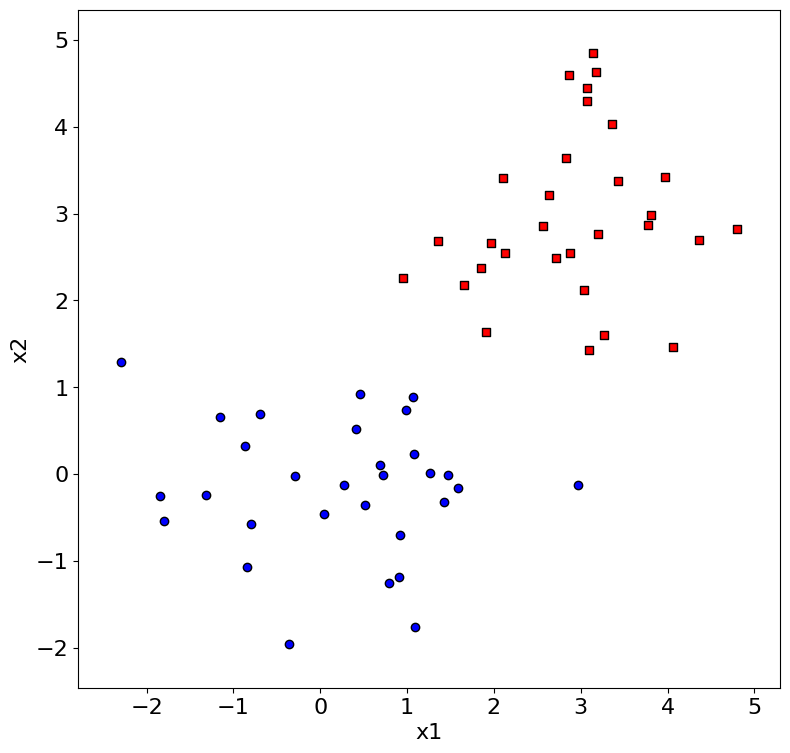

In [2]:
#@title 例題用のデータを生成します．
import numpy as np
npos = 30
nneg = 30
np.random.seed(321)
X = np.r_[np.random.randn(npos, 2) + [3, 3], np.random.randn(nneg, 2)]
# [1,1,...,1,-1,-1,...,-1]
y = np.array([1] * npos + [-1] * nneg)

plot2cls(X, y).plot_data()

### 損失関数を定義します．

In [3]:
import numpy as np

def LogisticLoss(y, g):
    return np.mean(np.log(1.0 + np.exp(-y*g)))

def HingeLoss(y, g):
    return np.mean(np.maximum(1.0 - y*g, 0.0))

# 線形識別関数
def g(X, w):
    return w[0] + np.dot(X, w[1:])

### $[w_0, w_1, w_2]^\top$はパーセプトロンの重みです．表示される損失関数の値がなるべく小さくなるように調整してください．
    1. どのようなとき，損失が大きく・小さくなりますか．

Logistic lossは，点が境界から遠いほど小さくなり，0にはならないので，ずっと重みを大きくしようとします。Hinge lossは，点が境界から十分離れれば0になるので，そこで止まります。

Logistic lossが一番小さくなったのはw₀=−5.0，w₁=1.1，w₂=3.0のときで，loss=0.0238でした。Hinge lossはw₀=−3.6，w₁=0.4，w₂=2.4のときに0になりました。

間違って分類された点が多いときや，正しく分類されていても点が決定境界の近くにあるときは，lossが大きくなります。すべての点が正しく分類されて，境界から離れているときは，lossが小さくなります。Logistic lossは，境界の位置が同じでも重みを大きくするとさらに小さくなるので，w₀がスライダーの端の−5まで行きました。Hinge lossは，すべての点が境界から十分離れると0になるので，それ以上重みを大きくする必要はありません。


    2. w0, w1, w2 によって決定境界はどのように変わりますか．

決定境界は w₀ + w₁x₁ + w₂x₂ = 0 の直線で，x₂ = −(w₁/w₂)x₁ − w₀/w₂ と書き直せます。なので，直線の傾きは −w₁/w₂ で，w₁とw₂の比で決まります。w₂に比べてw₁が大きいほど，直線は急になります。w₁とw₂が同じ符号なら右下がり，違う符号なら右上がりになります。w₁=0なら水平，w₂=0なら垂直の直線になります。

切片は −w₀/w₂ なので，w₀を変えると，傾きは変わらずに直線が平行に移動します。また，w₀，w₁，w₂を全部同じ倍率で大きくしても，傾きも切片も変わらないので，直線の位置は変わりません。






 Logistic loss = 1.830542,  Hinge loss =2.156992 




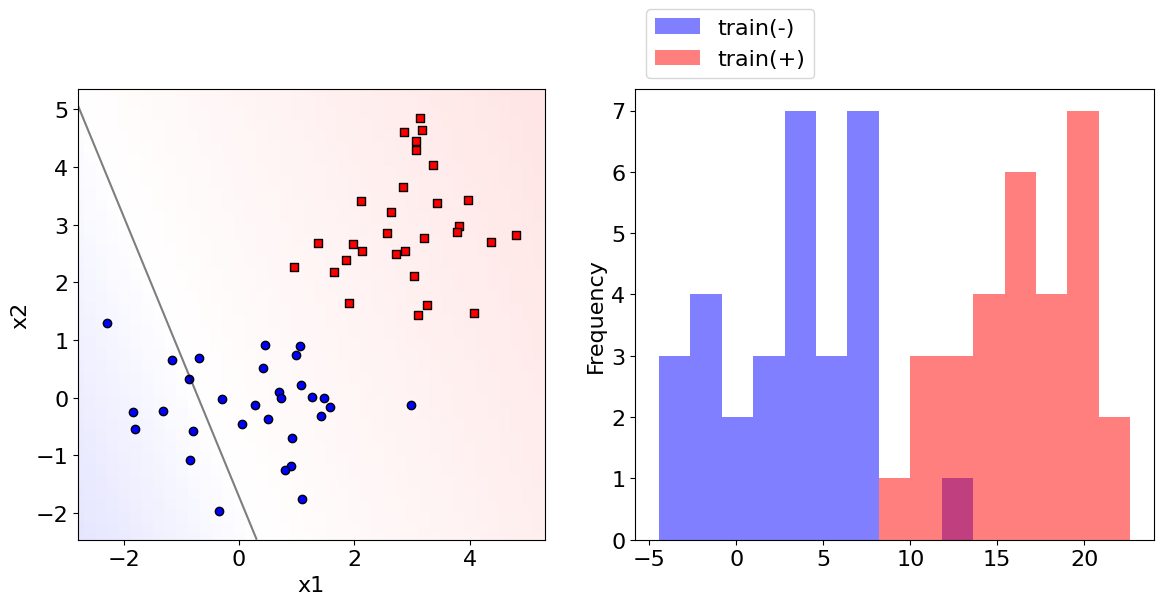

In [25]:
#@title {run: "auto"}
w0 = 2.4 #@param{type:"slider", min:-5, max:5, step:0.1}
w1 = 3.4 #@param{type:"slider", min:-5, max:5, step:0.1}
w2 = 1.4 #@param{type:"slider", min:-5, max:5, step:0.1}
w = np.array( [w0, w1, w2] )

ll = LogisticLoss(y, g(X, w))
hl = HingeLoss(y, g(X, w))
print('\n'*2, "Logistic loss = %f,  Hinge loss =%f" % (ll, hl), '\n'*2)
plotter = plot2cls(X, y, lambda X: g(X, w), levels={0.0:'-'}, dx=0.2)
plotter.plot_clf()
#plotter.plot_data()
#plotter.plot_hist()

In [15]:
import numpy as np
from scipy.optimize import minimize

bounds = [(-5, 5)] * 3
w_init = np.array([0.0, 0.0, 0.0])

for name, lossf in [("Logistic", LogisticLoss), ("Hinge", HingeLoss)]:
    res = minimize(lambda w: lossf(y, g(X, w)), w_init,
                   bounds=bounds, method="Powell")
    w_best = np.round(res.x, 1)
    print(f"{name}: w0={w_best[0]}, w1={w_best[1]}, w2={w_best[2]}, "
          f"loss={lossf(y, g(X, w_best)):.4f}")

Logistic: w0=-5.0, w1=1.1, w2=3.0, loss=0.0238
Hinge: w0=-3.6, w1=0.4, w2=2.4, loss=0.0000
